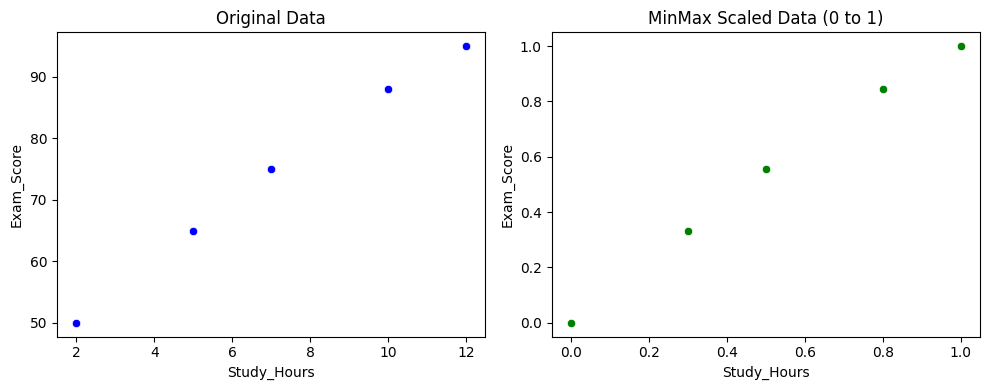

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 1. Create simple dataset
data = {
    'Study_Hours': [2, 5, 7, 10, 12],
    'Exam_Score': [50, 65, 75, 88, 95]
}
df = pd.DataFrame(data)

# 2. Apply MinMaxScaler
scaler = MinMaxScaler()
df_scaled = df.copy()
df_scaled[['Study_Hours', 'Exam_Score']] = scaler.fit_transform(df[['Study_Hours', 'Exam_Score']])

# 3. Visualize using Seaborn
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.scatterplot(data=df, x='Study_Hours', y='Exam_Score', ax=axes[0], color='blue')
axes[0].set_title('Original Data')

sns.scatterplot(data=df_scaled, x='Study_Hours', y='Exam_Score', ax=axes[1], color='green')
axes[1].set_title('MinMax Scaled Data (0 to 1)')

plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Create simple dataset
data = {
    'Height_cm': [155, 162, 170, 178, 185, 190],
    'Weight_kg': [50, 60, 68, 75, 82, 95]
}
df = pd.DataFrame(data)

# 2. Apply StandardScaler
scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df),
    columns=df.columns
)

# 3. Check statistics
print("--- Original Statistics ---")
print(df.describe().round(2))

print("\n--- Standardized Statistics ---")
print(df_scaled.describe().round(2)) # Mean becomes ~0.0 and Std becomes 1.0

--- Original Statistics ---
       Height_cm  Weight_kg
count       6.00       6.00
mean      173.33      71.67
std        13.50      16.01
min       155.00      50.00
25%       164.00      62.00
50%       174.00      71.50
75%       183.25      80.25
max       190.00      95.00

--- Standardized Statistics ---
       Height_cm  Weight_kg
count       6.00       6.00
mean       -0.00      -0.00
std         1.10       1.10
min        -1.49      -1.48
25%        -0.76      -0.66
50%         0.05      -0.01
75%         0.80       0.59
max         1.35       1.60


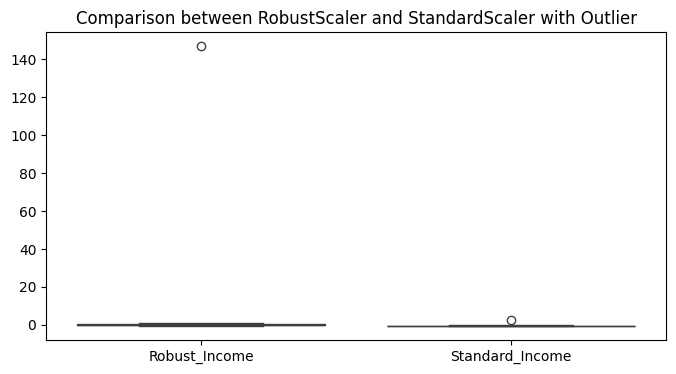

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler, StandardScaler

# 1. Dataset with an outlier
data = {
    'Income': [2000, 2200, 2500, 2100, 2300, 50000] # 50000 is an outlier
}
df = pd.DataFrame(data)

# 2. Apply RobustScaler and StandardScaler
robust_scaler = RobustScaler()
standard_scaler = StandardScaler()

df['Robust_Income'] = robust_scaler.fit_transform(df[['Income']])
df['Standard_Income'] = standard_scaler.fit_transform(df[['Income']])

# 3. Compare Distributions
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[['Robust_Income', 'Standard_Income']])
plt.title('Comparison between RobustScaler and StandardScaler with Outlier')
plt.show()

In [1]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

X, y = load_wine(return_X_y=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(),
    "LogReg": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(random_state=42),
}
scalers = {
    "None": "passthrough",
    "Standard": StandardScaler(),
    "MinMax": MinMaxScaler(),
    "Robust": RobustScaler(),
}

results = []
for m_name, model in models.items():
    for s_name, scaler in scalers.items():
        pipe = make_pipeline(scaler, model)
        score = cross_val_score(pipe, X, y, cv=cv).mean()
        results.append({"model": m_name, "scaler": s_name, "accuracy": score})

df = pd.DataFrame(results).pivot(index="model", columns="scaler", values="accuracy")
print(df.round(3))

/home/emad/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/emad/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable

scaler        MinMax   None  Robust  Standard
model                                        
KNN            0.961  0.680   0.961     0.972
LogReg         0.989  0.955   0.983     0.983
RandomForest   0.977  0.977   0.977     0.977
SVM            0.989  0.674   0.978     0.983


In [2]:
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, PowerTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

skewed = ["Population", "AveRooms", "AveBedrms", "AveOccup"]
others = [c for c in X.columns if c not in skewed]

preprocess = ColumnTransformer([
    ("skewed", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson")),
    ]), skewed),
    ("others", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", RobustScaler()),
    ]), others),
])

model = TransformedTargetRegressor(
    regressor=Pipeline([("prep", preprocess), ("ridge", Ridge(alpha=1.0))]),
    func=np.log1p, inverse_func=np.expm1,
)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(f"MAE: {mean_absolute_error(y_test, pred):.3f} | R2: {r2_score(y_test, pred):.3f}")

MAE: 0.481 | R2: 0.589
